# **Proyecto: Simulación de proceso de guerrillas utilizando el modelo de coalescencia - fragmentación de grupos guerrilleros - VERSION PHYTON**

Presentado por:

* Juan Esteban Gómez Gómez
* Jose Luis Martinez Diaz
* William David Rincón Verano
* Serena Triviño Sáenz


## Objetivo

Este código simula el modelo estocástico descrito en el artículo de Johnson *et al.* (2005), "From old wars to new wars and global terrorism". Se reproduce la distribución de tamaños para $N=10,000$ y $\nu=0.01$. El objetivo es estudiar el comportamiento del sistema la variar $\nu$.

## Introducción: Explicación del modelo de coalescencia-fragmentación de grupos guerrilleros

El modelo de coalescencia-fragmentación propuesto por Johnson *et al.* describe la evolución de grupos guerrilleros mediante dos procesos: la **coalescencia**, en la que dos grupos se unen para formar uno más grande, y la **fragmentación**, en la que un grupo se divide en unidades individuales. El objetivo es estudiar cómo estos mecanismos influyen en la distribución de tamaños de los grupos a lo largo del tiempo.

La simulación comienza con $N$ unidades, cada una perteneciente a un grupo de tamaño uno. En cada paso, se selecciona un grupo con una probabilidad proporcional a su tamaño. Después, ocurren dos posibles eventos:

- **Fragmentación:** con probabilidad $\nu$, el grupo seleccionado se divide en unidades individuales.
- **Coalescencia:** con probabilidad $1-\nu$, el grupo seleccionado se une a otro grupo, también elegido de acuerdo con su tamaño. Ambos forman un único grupo.

El parámetro $\nu$ controla la probabilidad de fragmentación, mientras que $N$ representa el número total de unidades del sistema. Durante la evolución, el número de grupos puede cambiar, pero el número total de unidades se conserva:

$$
\sum_{s=1}^{N} s\,n_s=N,
$$

donde $n_s$ es el número de grupos de tamaño $s$.

Mediante la simulación, se busca analizar la distribución de tamaños de los grupos y compararla con el comportamiento descrito en el artículo de referencia. En particular, se estudia si la distribución presenta un comportamiento aproximado de ley de potencias para ciertos tamaños de grupo.

**Referencia bibliográfica**

Johnson, N., Spagat, M., Restrepo, J. A., & Suárez, N. (2005). *From old wars to new wars and global terrorism*. Documentos de Economía, 2745, Universidad Javeriana, Bogotá. [Enlace al documento](https://ideas.repec.org/p/col/000108/002745.html).

Restrepo, J. A., Spagat, M., Johnson, N. F., Bohorquez, J. C., Suárez, N., Restrepo, E. M., Becerra, O., & Zarama, R. (2006). *Universal patterns underlying ongoing wars and terrorism?* arXiv. [Enlace al documento](https://doi.org/10.48550/arXiv.physics/0605035)

---

## 1. Librerías y parámetros iniciales


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

N = 30_000
NU = 0.01
BARRIDOS = 300 # El número de barridos se toma según la estabilidad de las gráficas, observada empíricamente.
SEMILLA = 42 # Número para usar en la generación de números aleatorios.

rng = np.random.default_rng(SEMILLA)
print(f"N={N:,}, nu={NU}, barridos={BARRIDOS}, pasos={N*BARRIDOS:,}")

N=30,000, nu=0.01, barridos=300, pasos=9,000,000


## 2. Definición de funciones

La lista `tamanos` contiene el tamaño de cada grupo. La selección asigna probabilidad `s_i / N` a cada grupo (proporcional a su tamaño). Para seleccionar el segundo grupo se retira temporalmente el primero; así el segundo es necesariamente distinto.

In [ ]:
def seleccionar_grupo(tamanos, rng):
    """Elige un grupo con probabilidad proporcional a su tamaño."""
    pesos = np.asarray(tamanos, dtype=float)
    probabilidades = pesos / pesos.sum()
    return int(rng.choice(len(tamanos), p=probabilidades))


def paso(tamanos, nu, rng):
    """Ejecuta un paso: La fragmentación ocurre con probabilidad nu, y ocurre fusión en otro caso."""
    tamanos = list(tamanos)
    i = seleccionar_grupo(tamanos, rng)
    si = tamanos.pop(i)
    if rng.random() < nu:
        # Fragmentación completa: s_i unidades nuevas de tamaño 1.
        tamanos.extend([1] * si)
    elif len(tamanos) == 0:
        # Caso límite: cuando solo hay un grupo, no existe otro con el cual fusionarlo.
        tamanos.append(si)
    else:
        # Fusión con otro grupo seleccionado proporcionalmente a su tamaño.
        j = seleccionar_grupo(tamanos, rng)
        sj = tamanos.pop(j)
        tamanos.append(si + sj)

    return tamanos


def contar_tamanos(tamanos, N):
    """Cuenta el numero de grupo de tamaño s"""
    n_s = np.zeros(N + 1, dtype=np.int64)
    valores, conteos = np.unique(tamanos, return_counts=True)
    n_s[valores] = conteos
    return n_s

## 3. Ejecutación de la simulación

Un **paso** es un evento de fragmentación o fusión. En este notebook, un **barrido** son $N$ pasos. Guardamos el número de grupos y el número de grupos unitarios una vez por barrido. También comprobamos que la suma de los tamaños siga siendo **N**.

In [ ]:
estado = [1] * N
historial_M = [] # Cantidad total de grupos
historial_n1 = [] # Cantidad de grupos de tamaño 1

inicio = time.time()
for b in range(BARRIDOS):
    for _ in range(N):
        estado = paso(estado, NU, rng)

    # Comprobación de la condición de la suma
    assert sum(estado) == N
    historial_M.append(len(estado))
    historial_n1.append(estado.count(1))

print(f"Tiempo transcurrido: {time.time()-inicio:.1f} s")
print(f"Grupos al final: {len(estado):,}")
print(f"Suma de tamaños: {sum(estado):,} (si es igual a {N:,}, todo nice)")

Tiempo transcurrido: 28406.1 s
Grupos al final: 15,729
Suma de tamaños: 30,000 (si es igual a 30,000, todo nice)


## 4. Gráficas de evolución temporal de grupos y grupos unitarios

Las gráficas muestran una tendencia que también depende del tiempo que dura la simulación corriendo. Esto ayuda a ver si las cantidades fluctúan alrededor de una zona estable, pero no prueban que haya un estado estacionario. Si las curvas no muestran una tendencia clara, es signo de que la variable `BARRIDOS` no es lo suficientemente grande.

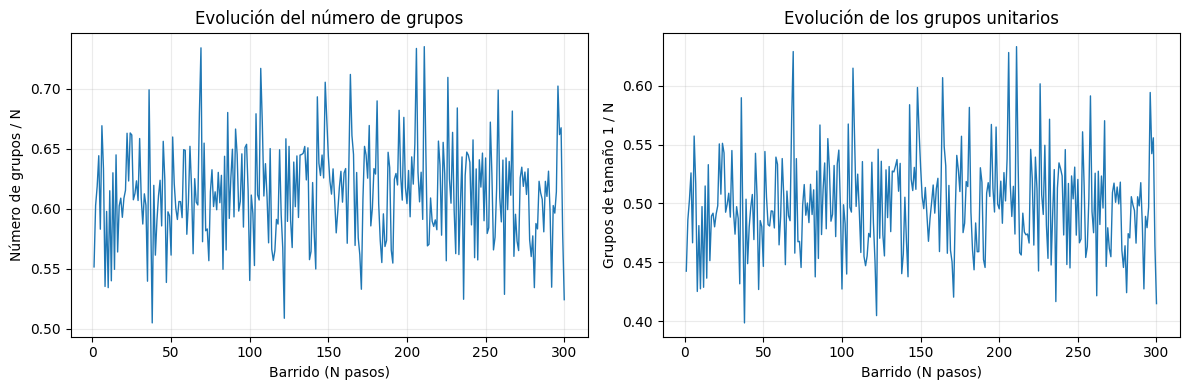

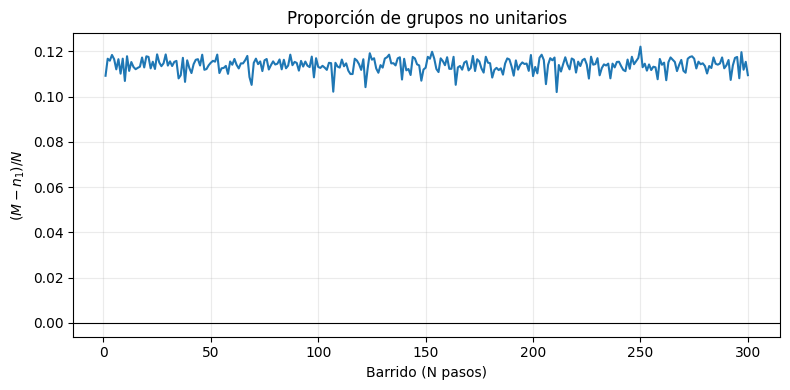

In [ ]:
barridos = np.arange(1, BARRIDOS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(barridos, np.array(historial_M) / N, lw=1)
ax[0].set_xlabel("Barrido (N pasos)")
ax[0].set_ylabel("Número de grupos / N")
ax[0].set_title("Evolución del número de grupos")
ax[1].plot(barridos, np.array(historial_n1) / N, lw=1)
ax[1].set_xlabel("Barrido (N pasos)")
ax[1].set_ylabel("Grupos de tamaño 1 / N")
ax[1].set_title("Evolución de los grupos unitarios")
for a in ax: a.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Comparación entre la evolución del número de grupos y los grupos unitarios. Se verifica que no tienen el mismo comportamiento.

M_norm = np.array(historial_M) / N
n1_norm = np.array(historial_n1) / N

plt.figure(figsize=(8, 4))
plt.plot(barridos, M_norm - n1_norm)
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("Barrido (N pasos)")
plt.ylabel(r"$(M-n_1)/N$")
plt.title("Proporción de grupos no unitarios")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Distribución final de tamaños

La figura de referencia dentro del artículo muestra el número de grupos `n_s` en función del tamaño `s`, en escala log-log. Así pues, se grafica `n_s / n_1` para normalizar la distribución como en la figura suplementaria. Los puntos con conteo nulo no se puede mostrar en la escala logarítmica, así que esto debe tenerse en cuenta.

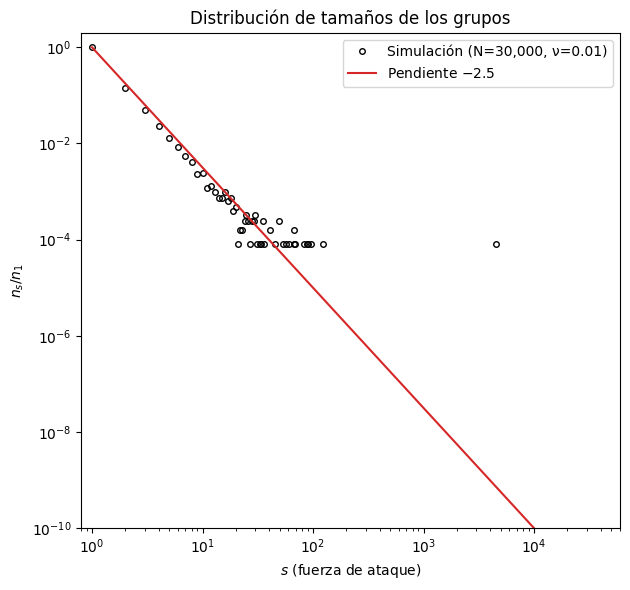

In [ ]:
n_s = contar_tamanos(estado, N)
s = np.arange(1, N + 1)
mascara = n_s[1:] > 0

fig, ax = plt.subplots(figsize=(6.4, 6))

ax.loglog(
    s[mascara],
    n_s[1:][mascara] / n_s[1],
    "o",
    mfc="none",
    ms=4,
    color="k",
    label=f"Simulación (N={N:,}, ν={NU})"
)

sg = np.logspace(0, np.log10(2*N), 100)
ax.loglog(
    sg,
    sg**-2.5,
    "-",
    color="C3",
    lw=1.5,
    label=r"Pendiente $-2.5$"
)

ax.set_xlabel(r"$s$ (fuerza de ataque)")
ax.set_ylabel(r"$n_s/n_1$")
ax.set(
    xlim=(0.8, 2*N),
    ylim=(1e-10, 2),
    title="Distribución de tamaños de los grupos"
)

ax.legend()
plt.tight_layout()
plt.show()

## 6. Estimación de la pendiente

En la región aproximadamente "recta" de una gráfica log-log, una ley de potencias `n_s ∝ s^(-alpha)` tiene pendiente `-alpha`. Este ajuste lineal está muy simplificado, solo es exploratorio y de verificación parcial, pues depende del intervalo elegido y además no demuestra que exista una ley de potencias por si solo.

Intervalo de ajuste: s entre 2 y 30
Pendiente log-log = -2.538
Exponente exploratorio alpha = 2.538


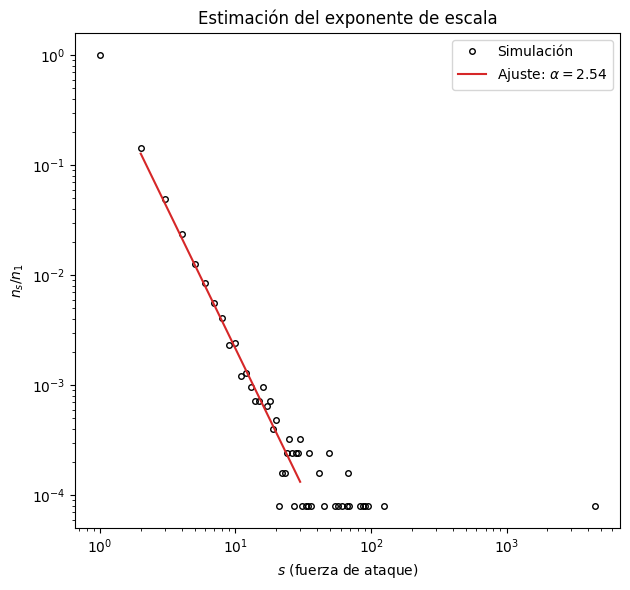

In [ ]:
S_MIN = 2
S_MAX = 30

m = (s >= S_MIN) & (s <= S_MAX) & (n_s[1:] > 0)

if m.sum() >= 2:
    pendiente, intercepto = np.polyfit(
        np.log10(s[m]),
        np.log10(n_s[1:][m]),
        1
    )
    alpha = -pendiente

    print(f"Intervalo de ajuste: s entre {S_MIN} y {S_MAX}")
    print(f"Pendiente log-log = {pendiente:.3f}")
    print(f"Exponente exploratorio alpha = {alpha:.3f}")

    fig, ax = plt.subplots(figsize=(6.4, 6))

    ax.loglog(
        s[mascara],
        n_s[1:][mascara] / n_s[1],
        "o",
        mfc="none",
        ms=4,
        color="k",
        label="Simulación"
    )

    ax.loglog(
        s[m],
        10**intercepto * s[m]**pendiente / n_s[1],
        "-",
        color="C3",
        lw=1.5,
        label=fr"Ajuste: $\alpha={alpha:.2f}$"
    )

    ax.set_xlabel(r"$s$ (fuerza de ataque)")
    ax.set_ylabel(r"$n_s/n_1$")
    ax.set_title("Distribución de tamaños de los grupos")
    ax.legend()

    plt.tight_layout()
    plt.show()

else:
    print("No hay suficientes tamaños en el intervalo para realizar el ajuste. Revisa S_MIN y S_MAX.")

## 7. Variación del parámentro $\nu$

Para cada valor de $\nu$, se realiza un barrido independiente y comparamos la distribución final. El tiempo de ejecución de esta parte es más corto, pero puede ser más largo. Además, también depende de la semilla.

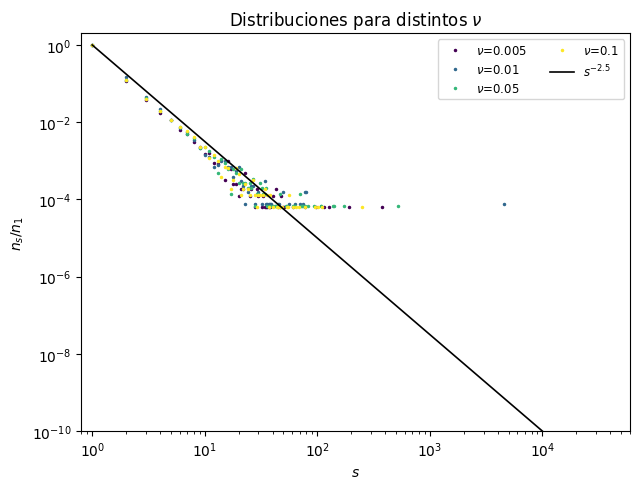

ν=0.005: α aproximado=2.605
ν=0.010: α aproximado=2.586
ν=0.050: α aproximado=2.514
ν=0.100: α aproximado=2.634


In [ ]:
def simular(N, nu, barridos, semilla):
    rng_local = np.random.default_rng(semilla)
    estado = [1] * N
    for _ in range(barridos):
        for _ in range(N):
            estado = paso(estado, nu, rng_local)
    return estado

BARRIDOS_NU = 20
VALORES_NU = [0.005, 0.01, 0.05, 0.1]

resultados_alpha = []

colores = plt.cm.viridis(np.linspace(0, 1, len(VALORES_NU)))
s_guia = np.logspace(0, np.log10(2*N), 100)

fig, ax = plt.subplots(figsize=(6.5, 5))

for k, nu in enumerate(VALORES_NU):
    estado_nu = simular(N, nu, BARRIDOS_NU, SEMILLA + k + 1)
    dist = contar_tamanos(estado_nu, N)

    ss = np.arange(1, N + 1)
    ok = dist[1:] > 0

    ax.loglog(
        ss[ok],
        dist[1:][ok] / dist[1],
        ".",
        ms=3,
        color=colores[k],
        label=fr"$\nu$={nu}"
    )

    intervalo = (
        (ss >= S_MIN) &
        (ss <= S_MAX) &
        (dist[1:] > 0)
    )

    if intervalo.sum() >= 2:
        p, _ = np.polyfit(
            np.log10(ss[intervalo]),
            np.log10(dist[1:][intervalo]),
            1
        )
        resultados_alpha.append((nu, -p))

ax.loglog(
    s_guia,
    s_guia**-2.5,
    "k-",
    lw=1.2,
    label=r"$s^{-2.5}$"
)

ax.set(
    xlim=(0.8, 2*N),
    ylim=(1e-10, 2),
    title=r"Distribuciones para distintos $\nu$"
)

ax.set_xlabel(r"$s$")
ax.set_ylabel(r"$n_s/n_1$")
ax.legend(fontsize=8.5, ncol=2, loc="upper right")

plt.tight_layout()
plt.show()

for nu, alpha in resultados_alpha:
    print(f"ν={nu:.3f}: α aproximado={alpha:.3f}")